# MLP: Multi-layer perceptron

[link to video](https://www.youtube.com/watch?v=TCH_1BHY58I&list=PLAqhIrjkxbuWI23v9cThsA9GvCAUhRvKZ&index=4&ab_channel=AndrejKarpathy)

In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [ ]:
len(words)

32033

In [ ]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

In [ ]:
#build the dataset

block_size = 3 # context length: how many characters do we take to predict the next one?
X,Y = [], []

for w in words[:5]:
  print(w)
  context = [0] * block_size
  for ch in w + '.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)
    print(''.join(itos[i] for i in context), '--->', itos[ix])
    context = context[1:] + [ix]

X= torch.tensor(X)
Y= torch.tensor(Y)

emma
... ---> e
..e ---> m
.em ---> m
emm ---> a
mma ---> .
olivia
... ---> o
..o ---> l
.ol ---> i
oli ---> v
liv ---> i
ivi ---> a
via ---> .
ava
... ---> a
..a ---> v
.av ---> a
ava ---> .
isabella
... ---> i
..i ---> s
.is ---> a
isa ---> b
sab ---> e
abe ---> l
bel ---> l
ell ---> a
lla ---> .
sophia
... ---> s
..s ---> o
.so ---> p
sop ---> h
oph ---> i
phi ---> a
hia ---> .


In [ ]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([32, 3]), torch.int64, torch.Size([32]), torch.int64)

In [ ]:
C = torch.randn((27, 2)) # 27 chars * 2 dim embeddings

In [ ]:
C[5]

tensor([-0.1378, -0.1827])

In [ ]:
F.one_hot(torch.tensor(5), num_classes=27).float() @ C

tensor([-0.1378, -0.1827])

In [ ]:
# we can directly index the integer, one hot is computationally intensive

In [ ]:
# we can also index with a list or tesnor
C[torch.tensor([5,6,7,5])]

tensor([[-0.1378, -0.1827],
        [ 0.3956,  0.3327],
        [-0.1797,  0.3804],
        [-0.1378, -0.1827]])

In [ ]:
emb = C[X]
emb.shape

torch.Size([32, 3, 2])

In [ ]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [ ]:
# h = emb.view(emb.shape[0], 6) @ W1 + b1

In [ ]:
# we can also use -1 in .view which means that torch will infer that dimension
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)

In [ ]:
h.shape

torch.Size([32, 100])

In [ ]:
W2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [ ]:
logits = h @ W2 + b2

In [ ]:
logits.shape

torch.Size([32, 27])

In [ ]:
counts = logits.exp()

In [ ]:
prob = counts / counts.sum(1, keepdims=True)

In [ ]:
prob.shape

torch.Size([32, 27])

In [ ]:
prob[0].sum() # check if  == 1 to see if normalization is working

tensor(1.)

In [ ]:
loss = -prob[torch.arange(32), Y].log().mean()
loss

tensor(14.7789)

In [ ]:
torch.arange(32)

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])

In [ ]:
Y

tensor([ 5, 13, 13,  1,  0, 15, 12,  9, 22,  9,  1,  0,  1, 22,  1,  0,  9, 19,
         1,  2,  5, 12, 12,  1,  0, 19, 15, 16,  8,  9,  1,  0])

# rewriting to make it more readable and reproduceable

In [ ]:
# build the dataset
def build_dataset(words):
  block_size = 4 # context length: how many characters do we take to predict the next one?
  X,Y = [], []
  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix]

  X= torch.tensor(X)
  Y= torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182441, 4]) torch.Size([182441])
torch.Size([22902, 4]) torch.Size([22902])
torch.Size([22803, 4]) torch.Size([22803])


In [ ]:
Xtr.shape, Ytr.shape # dataset

(torch.Size([182441, 4]), torch.Size([182441]))

In [ ]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((40, 300), generator=g)
b1 = torch.randn(300, generator=g)
W2 = torch.randn((300, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [ ]:
sum(p.nelement() for p in parameters) # number of parameters in total

20697

In [ ]:
for p in parameters:
  p.requires_grad = True

In [ ]:
lri =[]
lossi = []
stepi = []
pos = 1

In [ ]:


for i in range(30000):
  #minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (128,))

  # forward pass
  emb = C[Xtr[ix]] # (32,3,2)
  h = torch.tanh(emb.view(-1,40) @ W1 + b1) # (32,100)
  logits = h @ W2 + b2 # (32,27)
  loss = F.cross_entropy(logits, Ytr[ix])
  # print(loss.item())

  # backward pass
  for p in parameters:
    p.grad = None # same as setting to 0 in pytorch
  loss.backward()

  # update
  lr = 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  lossi.append(loss.log10().item())
  stepi.append(pos)
  pos+=1
  # lri.append(lre[i])

# print(loss.item())

NameError: name 'torch' is not defined

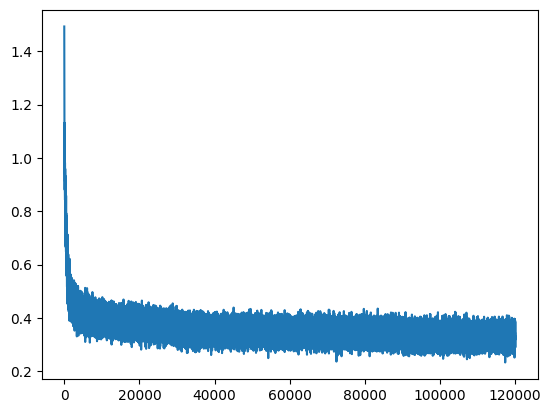

In [ ]:
plt.plot(stepi, lossi)

In [ ]:
# full loss dev set
emb = C[Xdev]
h = torch.tanh(emb.view(-1,40) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.2047, grad_fn=<NllLossBackward0>)

In [ ]:
# full loss train set
emb = C[Xtr]
h = torch.tanh(emb.view(-1,40) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.1543, grad_fn=<NllLossBackward0>)

In [ ]:
emb = C[Xte]
h = torch.tanh(emb.view(-1,40) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Yte)
loss

tensor(2.2105, grad_fn=<NllLossBackward0>)

In [ ]:
# sampling from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):

  out = []
  context = [0] * 4 # 3 is block_size
  while True:
    emb = C[torch.tensor([context])] # (1,3,2) (1, block_size, d)
    h = torch.tanh(emb.view(1,-1) @ W1 + b1)
    logits = h @ W2 + b2
    probs = F.softmax(logits, dim=1)
    ix = torch.multinomial(probs, num_samples=1, replacement=True, generator=g).item()
    context = context[1:] + [ix]
    out.append(ix)
    if ix == 0:
      break

  print(''.join(itos[i] for i in out))

carmah.
amelle.
khiigh.
xhea.
caslanden.
jazhne.
favesyn.
jarqui.
nerania.
chaiir.
kalenz.
dham.
jore.
quinn.
shoi.
raiva.
biuwanell.
dearynix.
kaeleighan.
edde.


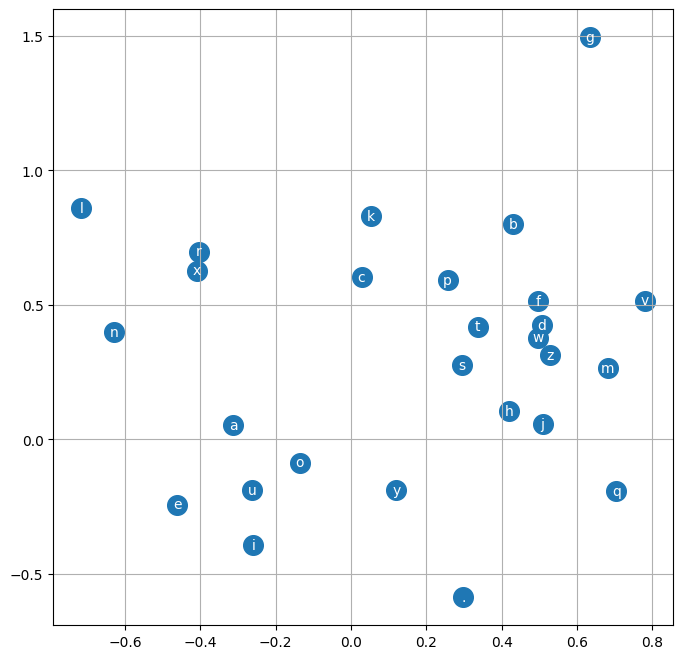

In [ ]:
# 2d embedding for characters. will now change it to 10 since this might be the bottle neck
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
  plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color="white")
plt.grid('minor')

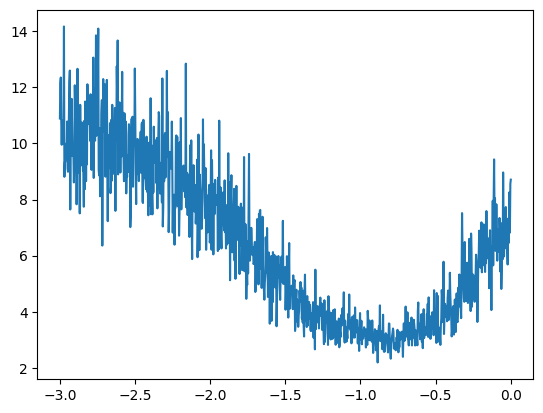

In [ ]:
plt.plot(lri, lossi)

In [ ]:
lre = torch.linspace(-3,0,1000)
lrs = 10**lre
lrs

tensor([0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0011,
        0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011,
        0.0011, 0.0011, 0.0011, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012,
        0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0013, 0.0013, 0.0013,
        0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0014,
        0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014,
        0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015,
        0.0015, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016,
        0.0016, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017,
        0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0019,
        0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0020, 0.0020,
        0.0020, 0.0020, 0.0020, 0.0020, 0.0020, 0.0021, 0.0021, 0.0021, 0.0021,
        0.0021, 0.0021, 0.0021, 0.0022, 

we can see the optimal learning rate = 10 ^ -1 = 0.01

In [ ]:
# we can see that when we use the whole dataset the computation takes longer, so in real life situations you would make smaller random
# batches of data and then train and back propagate for that specific batch

In [ ]:
# batch update
torch.randint(0, 5, (32,))

tensor([3, 1, 3, 1, 4, 2, 0, 2, 2, 1, 3, 2, 3, 1, 0, 1, 2, 3, 0, 0, 0, 4, 4, 2,
        3, 0, 4, 3, 2, 3, 0, 2])

In [ ]:
# we actually want x.shape size
torch.randint(0, X.shape[0], (32,))

tensor([217095,  45200, 205076, 173898,  18126, 163597, 221772, 102002,  38795,
        226063, 139105, 106570,  55241,  49245,  73321, 187297, 122687, 189587,
        204451,  29559, 165051,  83342,  76557, 144708, 193151, 120869, 174157,
        203652, 165640,  74409,  34061, 116021])

In [ ]:
F.cross_entropy(logits, Y)

tensor(10.7045, grad_fn=<NllLossBackward0>)

# stuff for changing dimensions in torch

In [ ]:
torch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]],1).shape

torch.Size([228146, 6])

In [ ]:
torch.cat(torch.unbind(emb, 1), 1).shape

torch.Size([228146, 6])

In [ ]:
a = torch.arange(18)
a

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17])

In [ ]:
a.shape

torch.Size([18])

In [ ]:
a.view(2,9)

tensor([[ 0,  1,  2,  3,  4,  5,  6,  7,  8],
        [ 9, 10, 11, 12, 13, 14, 15, 16, 17]])

In [ ]:
# view is very effecient

In [ ]:
a.storage()

/tmp/ipython-input-214256462.py:1: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  a.storage()


 0
 1
 2
 3
 4
 5
 6
 7
 8
 9
 10
 11
 12
 13
 14
 15
 16
 17
[torch.storage.TypedStorage(dtype=torch.int64, device=cpu) of size 18]

In [ ]:
emb.shape

torch.Size([228146, 3, 2])

In [ ]:
emb.view(32,6) == torch.cat(torch.unbind(emb, 1), 1)

RuntimeError: shape '[32, 6]' is invalid for input of size 1368876

# F.cross_entropy is better to use than calculating by
```
counts = logits.exp()
prob = counts / counts.sum(1, keepdims=True)
loss = -prob[torch.arange(32), Y].log().mean()
```
since it
- doesnt create new tensors that take up memory
- numerically more sound i.e more robust to small and large numbers as seen below

In [ ]:
logits = torch.tensor([-5,-3,0,5]) - 10
counts = logits.exp()
probs = counts / counts.sum()
probs

tensor([4.5079e-05, 3.3309e-04, 6.6903e-03, 9.9293e-01])

we see nan here coz there is an inf. val in counts since e^100 is very large. This is what F.cross_entropy fixes. it turns out that since we are normalizing, we can offset the logits by any arbitrary constant value here. try changing the value to see the probs are always same. pytorch offsets any tensor by max.